# Module 9 Part 2: Deep learning

This notebook follows the slide deck in order. Each heading names the slides it goes with.

| Part | Slides | What we do |
|---|---|---|
| 1 | 3-27 | Work out a tiny neural network by hand: forward pass, error, gradient descent, backpropagation |
| 2 | 28-34 | Build the same kind of network in Keras and predict wine quality |
| 3 | 35-55 | Convolution by hand: padding, strides, dilation, max pooling |
| 4 | 56-58 | A convolutional network reads handwritten digits |
| 5 | 59-63, 77 | Networks with memory: an LSTM forecasts airline passengers |
| 6 | 64-69 | Attention, the engine inside transformers |
| 7 | 70-76, 80 | Training tricks: epochs, batches, dropout, batch normalisation, regularisation; PyTorch; how ChatGPT was trained |

**Data used**

- Wine Quality (P. Cortez and others, 2009), UCI Machine Learning Repository, licence CC BY 4.0. File: `data/winequality_merged.csv`.
- Monthly international airline passengers, 1949-1960 (Box and Jenkins). File: `data/AirPassengers.csv`.
- MNIST handwritten digits (Y. LeCun, C. Cortes, C. Burges), licence CC BY-SA 3.0. Keras downloads it (about 11 MB) the first time.

**Before you start:** this notebook needs TensorFlow. If `import keras` fails, run `pip install tensorflow` in the `dsai` environment (Windows: Anaconda Prompt; Mac: Terminal, after `conda activate dsai`).

Neural networks start from random numbers. We fix the random seed so a re-run on the same computer gives the same results. On a different computer, or with a different seed, the numbers can differ, sometimes enough to change which model comes out ahead. The hand-worked numbers in Parts 1 and 3 are exact everywhere.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FOLDER = "../../../data/"   # the shared data folder at the top of the repo

# Part 1. A neural network by hand (slides 3-27)

## What does one artificial neuron do? (slide 5)

A neuron takes some numbers in, multiplies each by a **weight**, adds them up, adds a **bias**, and passes the total through an **activation function** $f$:

$$\text{out} = f\left(w_1 \cdot \text{in}_1 + w_2 \cdot \text{in}_2 + w_3 \cdot \text{in}_3 + b\right)$$

A real-life picture: a bank deciding on a loan. Income, savings and debts come in. Each gets a weight (debts count against you). The bias is the bank's starting mood. The activation decides what comes out.

Below is one neuron with made-up numbers, and no activation yet, so $f$ leaves the total as it is.

In [2]:
# made-up inputs and weights, for illustration only
inputs = [2.0, 3.0, 1.0]
weights = [0.5, -1.0, 2.0]
bias = 1.0

total = 0.0
for position in range(len(inputs)):
    contribution = inputs[position] * weights[position]   # one input times its weight
    print("input", inputs[position], "x weight", weights[position], "=", contribution)
    total = total + contribution

total = total + bias          # the bias is added once, at the end
print("plus bias", bias)
print("neuron output:", total)

input 2.0 x weight 0.5 = 1.0
input 3.0 x weight -1.0 = -3.0
input 1.0 x weight 2.0 = 2.0
plus bias 1.0
neuron output: 1.0


## The wine-maker's network (slides 8-13)

The slides predict wine **quality** from **sugar** and **sunny days**. In between sits a hidden layer of two neurons. Each hidden neuron mixes the inputs in its own way, which is how a network captures interactions between inputs (slides 8-9).

The weights on slide 10 are:

| From | To top hidden node | To bottom hidden node |
|---|---|---|
| Sugar (32) | 1 | -1 |
| Sunny days (5) | 1 | 2 |

and from the hidden nodes to the output: top 3, bottom 2. There are no biases in this example (all zero).

**Predict before we run:** work out the top hidden node, the bottom hidden node and the output on paper first.

In [3]:
sugar = 32
sunny_days = 5

# weights from slide 10
weight_sugar_to_top = 1
weight_sunny_to_top = 1
weight_sugar_to_bottom = -1
weight_sunny_to_bottom = 2
weight_top_to_output = 3
weight_bottom_to_output = 2

# hidden layer: multiply, then add
top_node = sugar * weight_sugar_to_top + sunny_days * weight_sunny_to_top
bottom_node = sugar * weight_sugar_to_bottom + sunny_days * weight_sunny_to_bottom
print("top hidden node:   ", top_node)
print("bottom hidden node:", bottom_node)

# output layer: multiply, then add again
quality = top_node * weight_top_to_output + bottom_node * weight_bottom_to_output
print("predicted quality: ", quality)

top hidden node:    37
bottom hidden node: -22
predicted quality:  67


### The same calculation as matrices

Libraries do not loop over neurons one by one. They put the weights in a table (a matrix) and do the whole layer in one multiplication, written `@` in NumPy. Row $i$, column $j$ of the weight matrix is the weight from input $i$ to hidden node $j$.

$$\text{hidden} = \begin{bmatrix} 32 & 5 \end{bmatrix} \begin{bmatrix} 1 & -1 \\ 1 & 2 \end{bmatrix}, \qquad \text{output} = \text{hidden} \begin{bmatrix} 3 \\ 2 \end{bmatrix}$$

The check at the end confirms both methods agree.

In [4]:
input_values = np.array([32, 5])
weights_layer_1 = np.array([[1, -1],     # from sugar
                            [1, 2]])     # from sunny days
weights_layer_2 = np.array([3, 2])       # from top and bottom hidden nodes

hidden_values = input_values @ weights_layer_1
output_value = hidden_values @ weights_layer_2

print("hidden layer:", hidden_values)
print("output:      ", output_value)

assert output_value == quality   # the loop answer and the matrix answer must match
print("check passed: loops and matrices agree")

hidden layer: [ 37 -22]
output:       67
check passed: loops and matrices agree


## Why do we need an activation function? (slides 15-16)

Slide 15 sorts functions into straight-line (linear) and curved (non-linear) ones. Here are the common activation functions.

**ReLU** (rectified linear unit) is the one used most:

$$\text{ReLU}(x) = \begin{cases} 0 & \text{if } x < 0 \\ x & \text{if } x \ge 0 \end{cases}$$

**Sigmoid** squashes any number into the range 0 to 1, and **tanh** into the range -1 to 1:

$$\sigma(x) = \frac{1}{1 + e^{-x}}, \qquad \tanh(x) = \frac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$$

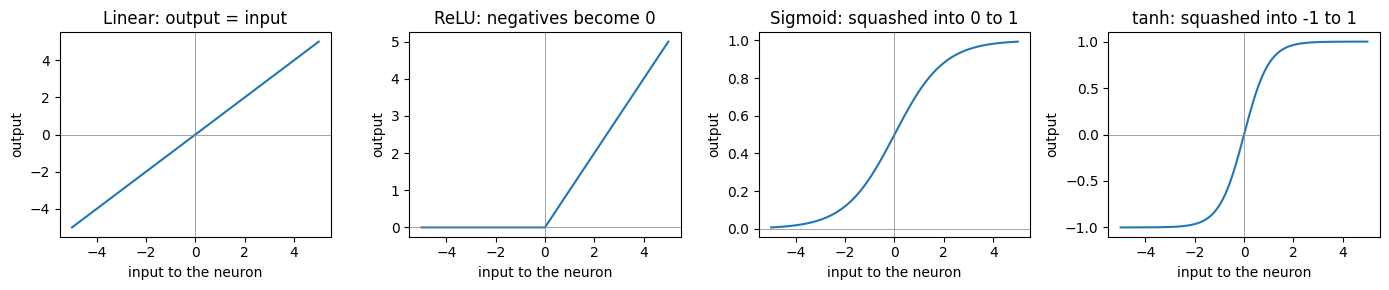

In [5]:
x_values = np.linspace(-5, 5, 201)

linear_values = x_values
relu_values = np.maximum(0, x_values)
sigmoid_values = 1 / (1 + np.exp(-x_values))
tanh_values = np.tanh(x_values)

figure, axes = plt.subplots(1, 4, figsize=(14, 3))
axes[0].plot(x_values, linear_values)
axes[0].set_title("Linear: output = input")
axes[1].plot(x_values, relu_values)
axes[1].set_title("ReLU: negatives become 0")
axes[2].plot(x_values, sigmoid_values)
axes[2].set_title("Sigmoid: squashed into 0 to 1")
axes[3].plot(x_values, tanh_values)
axes[3].set_title("tanh: squashed into -1 to 1")
for axis in axes:
    axis.axhline(0, color="grey", linewidth=0.5)
    axis.axvline(0, color="grey", linewidth=0.5)
    axis.set_xlabel("input to the neuron")
    axis.set_ylabel("output")
plt.tight_layout()
plt.show()

### A puzzle: is the hidden layer doing anything?

Our wine network had no activation function. Here are its two weight matrices multiplied together:

$$\begin{bmatrix} 1 & -1 \\ 1 & 2 \end{bmatrix} \begin{bmatrix} 3 \\ 2 \end{bmatrix} = \begin{bmatrix} 1 \cdot 3 + (-1) \cdot 2 \\ 1 \cdot 3 + 2 \cdot 2 \end{bmatrix}$$

**Predict before we run:** a network with *no* hidden layer, using those two combined weights, gets 32 and 5 as inputs. Will it give a different answer from our two-layer network?

In [6]:
combined_weights = weights_layer_1 @ weights_layer_2
print("combined weights (sugar, sunny days):", combined_weights)

one_layer_output = input_values @ combined_weights
print("one-layer network output:", one_layer_output)
print("two-layer network output:", output_value)

combined weights (sugar, sunny days): [1 7]
one-layer network output: 67
two-layer network output: 67


Same answer. Stacking layers without an activation function collapses into one layer, however many layers you stack. It can only ever draw straight lines.

Now put ReLU on the hidden nodes. The bottom node was negative, so ReLU turns it into 0.

In [7]:
hidden_after_relu = np.maximum(0, hidden_values)
print("hidden before ReLU:", hidden_values)
print("hidden after ReLU: ", hidden_after_relu)

output_with_relu = hidden_after_relu @ weights_layer_2
print("output with ReLU:   ", output_with_relu)
print("output without ReLU:", output_value)

hidden before ReLU: [ 37 -22]
hidden after ReLU:  [37  0]
output with ReLU:    111
output without ReLU: 67


The bend in ReLU at zero is what lets a network learn curved, non-straight relationships.

## Two hidden layers (slides 17-18)

Slide 17 adds a second hidden layer and uses ReLU after each hidden layer. Weights into the second hidden layer:

| From | To top node | To bottom node |
|---|---|---|
| first-layer top node | -3 | 5 |
| first-layer bottom node | 2 | 2 |

Output weights are again 3 (top) and 2 (bottom).

**Predict before we run:** work through it layer by layer. Remember ReLU after each hidden layer.

In [8]:
weights_hidden_1 = np.array([[1, -1],
                             [1, 2]])
weights_hidden_2 = np.array([[-3, 5],
                             [2, 2]])
weights_output = np.array([3, 2])

layer_1_before = input_values @ weights_hidden_1
layer_1_after = np.maximum(0, layer_1_before)
print("layer 1 before ReLU:", layer_1_before, "  after ReLU:", layer_1_after)

layer_2_before = layer_1_after @ weights_hidden_2
layer_2_after = np.maximum(0, layer_2_before)
print("layer 2 before ReLU:", layer_2_before, "  after ReLU:", layer_2_after)

final_output = layer_2_after @ weights_output
print("output:", final_output)

layer 1 before ReLU: [ 37 -22]   after ReLU: [37  0]
layer 2 before ReLU: [-111  185]   after ReLU: [  0 185]
output: 370


## What do the layers learn? (slide 19)

In a deep network trained on photos, early layers tend to respond to simple things such as edges, and later layers to bigger patterns built from them. Nobody tells the network to do this. It finds those internal features because they help reduce the error. That is why deep learning partly replaces hand-made feature engineering. We will see the "edge" idea for real in Part 3.

## How wrong is the prediction? (slides 20-22)

Our network said 67. The real quality of this wine was 56. The **error** is

$$\text{error} = \text{predicted} - \text{actual}$$

One wine is not enough to judge a model, so slide 22 lists ten. We square each error (so negatives do not cancel positives, and big misses count more) and take the average. This is the **mean squared error**:

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n} \left(\text{predicted}_i - \text{actual}_i\right)^2$$

**Predict before we run:** which single wine will contribute the most to the total?

In [9]:
# the ten wines from slide 22
actual_values = [56, 67, 149, 117, 29, 23, 64, 57, 36, 56]
predicted_values = [67, 50, 148, 99, 9, 42, 28, 39, 7, 23]

total_squared_error = 0
print("actual  predicted  error  squared")
for row in range(len(actual_values)):
    error = predicted_values[row] - actual_values[row]
    squared_error = error * error
    total_squared_error = total_squared_error + squared_error
    print(f"{actual_values[row]:6} {predicted_values[row]:10} {error:6} {squared_error:8}")

mean_squared_error_value = total_squared_error / len(actual_values)
print("total squared error:", total_squared_error)
print("mean squared error: ", mean_squared_error_value)

actual  predicted  error  squared
    56         67     11      121
    67         50    -17      289
   149        148     -1        1
   117         99    -18      324
    29          9    -20      400
    23         42     19      361
    64         28    -36     1296
    57         39    -18      324
    36          7    -29      841
    56         23    -33     1089
total squared error: 5046
mean squared error:  504.6


## Loss functions and gradient descent (slides 23-25)

The **loss function** turns all the errors into one number. Training means: find the weights that make the loss as small as possible.

Let us change only one weight, the one from the top hidden node to the output (now 3), and leave everything else alone. The prediction becomes

$$\text{prediction} = 37 \cdot w + (-22) \cdot 2 = 37w - 44$$

and the squared error for our wine with actual quality 56 is

$$E(w) = (37w - 44 - 56)^2$$

The slope of this curve tells us which way is downhill. By the chain rule from calculus ($(\frac{d}{dx}(ax-b)^{2}=2a(ax-b) $):

$$\frac{\partial E}{\partial w} = 2\times 37(37w - 44 - 56) = 2 \cdot (\text{prediction} - \text{actual}) \cdot 37$$

Gradient descent (slide 25) takes a small step downhill, with step size set by the learning rate $l$:

$$w_{\text{new}} = w_{\text{old}} - l \cdot \frac{\partial E}{\partial w}$$

**Predict before we run:** after 10 steps with learning rate 0.0002, will the prediction be above 56, below 56, or exactly 56?

In [10]:
hidden_top = 37
hidden_bottom = -22
weight_bottom = 2
actual_quality = 56

weight = 3.0             # starting weight, from the slide
learning_rate = 0.0002

weight_history = [weight]
print("step   weight    prediction   squared error")
for step in range(11):
    prediction = hidden_top * weight + hidden_bottom * weight_bottom
    squared_error = (prediction - actual_quality) ** 2
    print(f"{step:4} {weight:9.4f} {prediction:12.3f} {squared_error:14.4f}")
    slope = 2 * (prediction - actual_quality) * hidden_top   # the derivative
    weight = weight - learning_rate * slope                  # one step downhill
    weight_history.append(weight)

step   weight    prediction   squared error
   0    3.0000       67.000       121.0000
   1    2.8372       60.976        24.7646
   2    2.7635       58.251         5.0685
   3    2.7302       57.018         1.0373
   4    2.7152       56.461         0.2123
   5    2.7083       56.208         0.0435
   6    2.7053       56.094         0.0089
   7    2.7039       56.043         0.0018
   8    2.7032       56.019         0.0004
   9    2.7029       56.009         0.0001
  10    2.7028       56.004         0.0000


The prediction creeps towards 56 and the squared error shrinks every step. The exact best weight here is $w = 100 / 37$, which makes the prediction exactly 56. The picture shows the error curve and the steps taken along it.

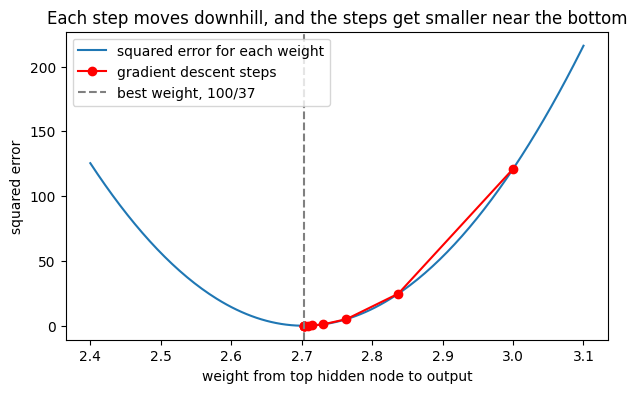

In [11]:
weight_grid = np.linspace(2.4, 3.1, 200)
error_grid = (hidden_top * weight_grid + hidden_bottom * weight_bottom - actual_quality) ** 2

steps_taken = np.array(weight_history[:11])
errors_at_steps = (hidden_top * steps_taken + hidden_bottom * weight_bottom - actual_quality) ** 2

plt.figure(figsize=(7, 4))
plt.plot(weight_grid, error_grid, label="squared error for each weight")
plt.plot(steps_taken, errors_at_steps, "o-", color="red", label="gradient descent steps")
plt.axvline(100 / 37, color="grey", linestyle="--", label="best weight, 100/37")
plt.xlabel("weight from top hidden node to output")
plt.ylabel("squared error")
plt.title("Each step moves downhill, and the steps get smaller near the bottom")
plt.legend()
plt.show()

### What if the learning rate is too big?

**Predict before we run:** same start, but learning rate 0.001, five times bigger. Faster to the bottom, or something else?

In [12]:
weight = 3.0
big_learning_rate = 0.001

print("step   weight    prediction")
for step in range(6):
    prediction = hidden_top * weight + hidden_bottom * weight_bottom
    print(f"{step:4} {weight:9.3f} {prediction:12.1f}")
    slope = 2 * (prediction - actual_quality) * hidden_top
    weight = weight - big_learning_rate * slope

step   weight    prediction
   0     3.000         67.0
   1     2.186         36.9
   2     3.601         89.2
   3     1.142         -1.7
   4     5.415        156.4
   5    -2.012       -118.4


Each step overshoots the bottom by more than the last, so the predictions swing further and further from 56. Too large a learning rate makes training fall apart. Too small makes it painfully slow. Choosing it is part of the craft.

The slides (24) also show a curve with two dips. Gradient descent only ever walks downhill from where it starts, so it can settle in the smaller dip. Because training starts from random weights, different runs can settle in different dips, which is one reason results vary between runs.

## Backpropagation: blame flows backwards (slides 25-26)

So far we nudged an output weight. What about a weight deep inside, such as the one from sugar to the top hidden node (now 1)? Its effect on the error travels through the top hidden node, then through the output. The chain rule multiplies the effects along that path:

$$\frac{\partial E}{\partial w_{\text{sugar}\to\text{top}}} = \underbrace{2(\text{prediction} - \text{actual})}_{\text{error to prediction}} \times \underbrace{3}_{\text{top node to prediction}} \times \underbrace{32}_{\text{weight to top node (the sugar input)}}$$

Backpropagation is doing this for every weight at once, starting at the output and working backwards, reusing the parts of the chain that weights share. That is why it is fast.

# Part 2. Keras (slides 28-34)

## TensorFlow, Keras and the Playground (slides 28-30)

- **TensorFlow** (from Google) does the heavy number work: matrix maths, the calculus for backpropagation, and running on CPUs, GPUs or TPUs.
- **Keras** is the friendly layer on top, where we describe the network. Since Keras 3 it can also run on JAX or PyTorch instead of TensorFlow.

**TensorFlow Playground (slide 29):** open https://playground.tensorflow.org in a browser. Try these and predict before pressing play:

1. Pick the **circle** dataset (blue dots inside a ring of orange). Use only the inputs $X_1$ and $X_2$ and remove all hidden layers. Can it separate the colours?
2. Add one hidden layer with 4 neurons. What changes?
3. Go back to no hidden layers, but also tick the inputs $X_1^2$ and $X_2^2$. What happens now, and why?
4. Try the **spiral** dataset. How many layers and neurons do you need?


In [13]:
import os


import keras
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Keras version:     ", keras.__version__)
print("Keras is running on:", keras.backend.backend())

TensorFlow version: 2.21.0
Keras version:      3.15.1
Keras is running on: tensorflow


## The real wine data

We now use a real dataset: 6,497 Portuguese wines (red and white), eleven lab measurements each, a column saying whether it is red (1) or white (0), and a quality score given by tasters. We will predict the quality score.

Some rows are exact copies of other rows. If a copy lands in the test set and its twin in the training set, the test score looks better than it should. So we keep one of each.

In [14]:
wine = pd.read_csv(DATA_FOLDER + "winequality_merged.csv")
print("rows, columns:", wine.shape)

number_of_copies = wine.duplicated().sum()
print("rows that are exact copies of an earlier row:", number_of_copies)

wine = wine.drop_duplicates()
print("rows after keeping one of each:", len(wine))

wine.head()

rows, columns: (6497, 13)
rows that are exact copies of an earlier row: 1177
rows after keeping one of each: 5320


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,red_wine
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


In [15]:
print("How many wines got each quality score:")
print(wine["quality"].value_counts().sort_index())

How many wines got each quality score:
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


### Split, then scale

We keep 20% of the wines aside as a **test set** that the model never sees during training.

Neural networks train badly when the inputs are on very different scales (total sulfur dioxide runs into the hundreds, density sits near 1). So we **standardise** each column: subtract its mean and divide by its standard deviation. The mean and standard deviation come from the training set only, so no information leaks from the test set.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features = wine.drop(columns="quality")
target = wine["quality"]

X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

scaler = StandardScaler()
scaler.fit(X_train)                        # learn mean and spread from training rows only
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

number_of_columns = X_train_scaled.shape[1]
print("training wines:", len(X_train_scaled))
print("test wines:    ", len(X_test_scaled))
print("input columns: ", number_of_columns)

training wines: 4256
test wines:     1064
input columns:  12


### Two models to beat

Before any neural network, two simple yardsticks:

1. **Guess the average.** Predict the training average quality for every wine.
2. **Linear regression**, from Module 4.

We measure all models by mean squared error on the test set. Lower is better.

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

average_quality = y_train.mean()
average_guesses = np.full(len(y_test), average_quality)
mse_average = mean_squared_error(y_test, average_guesses)
print("Guess the average, test MSE:", round(mse_average, 3))

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
mse_linear = mean_squared_error(y_test, linear_model.predict(X_test_scaled))
print("Linear regression, test MSE:", round(mse_linear, 3))

Guess the average, test MSE: 0.753
Linear regression, test MSE: 0.52


## Building the network (slides 31-32)

This is the network from slide 31: two hidden layers with 15 and 5 neurons and ReLU, and one output neuron with no activation (linear), because quality is a number. Current Keras wants the input size given by `keras.Input` at the start, rather than `input_shape=` inside the first layer.

**Predict before we run:** how many weights and biases does this network have? Each neuron has one weight per input plus one bias.

In [18]:
keras.utils.set_random_seed(42)   # same starting weights every run

wine_network = keras.Sequential([
    keras.Input(shape=(number_of_columns,)),          # 12 input columns
    keras.layers.Dense(15, activation="relu"),        # first hidden layer
    keras.layers.Dense(5, activation="relu"),         # second hidden layer
    keras.layers.Dense(1, activation="linear"),       # output: one number
])

#wine_network.summary()

In [19]:
# the same count by hand: (inputs + 1 bias) x neurons, for each layer
layer_sizes = [number_of_columns, 15, 5, 1]
total_parameters = 0
for layer in range(1, len(layer_sizes)):
    inputs_to_layer = layer_sizes[layer - 1]
    neurons = layer_sizes[layer]
    parameters = (inputs_to_layer + 1) * neurons
    print("layer", layer, ":", inputs_to_layer, "inputs + 1 bias, times", neurons, "neurons =", parameters)
    total_parameters = total_parameters + parameters

print("total by hand:", total_parameters)
assert total_parameters == wine_network.count_params()
print("check passed: matches Keras")

layer 1 : 12 inputs + 1 bias, times 15 neurons = 195
layer 2 : 15 inputs + 1 bias, times 5 neurons = 80
layer 3 : 5 inputs + 1 bias, times 1 neurons = 6
total by hand: 281
check passed: matches Keras


### Compile and fit (slide 32)

- `optimizer="adam"` is a smarter version of gradient descent that adapts the step size for each weight.
- `loss="mse"` is the mean squared error from slide 22.
- `validation_split=0.25` holds back the last 25% of the training rows to watch for overfitting while training.
- One **epoch** is one pass through all the training rows. The slide uses 1000 epochs; we use 100 to keep the class moving, and the plot will show whether that was enough.

**Predict before we run:** will the network beat linear regression on the test set?

In [20]:
wine_network.compile(optimizer="adam", loss="mse", metrics=["mse"])

history = wine_network.fit(
    X_train_scaled,
    y_train.to_numpy(),
    validation_split=0.25,
    epochs=100,
    verbose=0,          # 0 = train quietly
)
print("training finished after", len(history.history["loss"]), "epochs")

training finished after 100 epochs


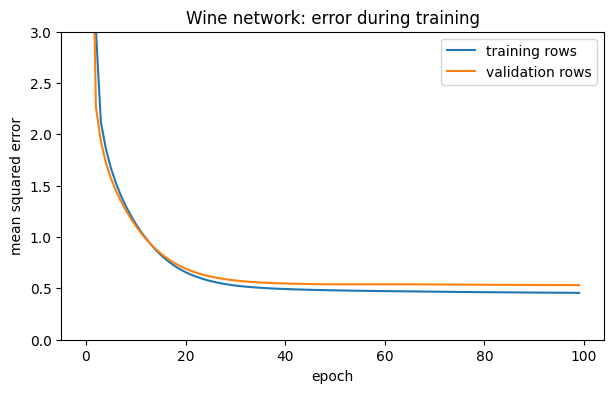

In [21]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="training rows")
plt.plot(history.history["val_loss"], label="validation rows")
plt.xlabel("epoch")
plt.ylabel("mean squared error")
plt.ylim(0, 3)
plt.title("Wine network: error during training")
plt.legend()
plt.show()

In [22]:
test_loss, test_mse = wine_network.evaluate(X_test_scaled, y_test.to_numpy(), verbose=0)
mse_network = test_mse

print("Test mean squared error (lower is better)")
print("  Guess the average: ", round(mse_average, 3))
print("  Linear regression: ", round(mse_linear, 3))
print("  Neural network:    ", round(mse_network, 3))

print()
print("In quality points (square root of MSE):")
print("  Guess the average: ", round(np.sqrt(mse_average), 2))
print("  Linear regression: ", round(np.sqrt(mse_linear), 2))
print("  Neural network:    ", round(np.sqrt(mse_network), 2))

Test mean squared error (lower is better)
  Guess the average:  0.753
  Linear regression:  0.52
  Neural network:     0.481

In quality points (square root of MSE):
  Guess the average:  0.87
  Linear regression:  0.72
  Neural network:     0.69


Read the result honestly. Both models beat guessing the average. Compare the network and linear regression by the size of the gap, not only which is lower. A network brings more weights, more choices (layers, epochs, learning rate) and less explanation of *why* it predicts what it does. On a small table of numbers, that trade is not always worth it. Neural networks pull far ahead on images, sound and text, which is where Parts 4 to 6 go.

### Which loss and output for which problem? (slide 32)

| Problem | Output neurons | Output activation | Loss |
|---|---|---|---|
| Regression (a number) | 1 | none (linear) | `mse` |
| Two classes | 1 | `sigmoid` | `binary_crossentropy` |
| Several classes, labels one-hot encoded | number of classes | `softmax` | `categorical_crossentropy` |
| Several classes, labels as whole numbers 0, 1, 2, ... | number of classes | `softmax` | `sparse_categorical_crossentropy` |

The last row is the one we use for the digits in Part 4, because their labels are plain numbers 0 to 9.

**Lab 9.1 (slide 34), try it yourself:** change the hidden layer sizes, add a third layer, or change the number of epochs, and see what happens to the test MSE. Change one thing at a time and write down what you changed.